# 02 — A planet around a mass-losing star 

**Physics**: isotropic adiabatic stellar mass loss only. No direct N-body integration, no tides, no brown dwarf (This will be the next thing I think)
(Its good to note down what physics we are using in each notebook. It helps with interpreting our results.)


The adiabatic relation is

$a(t)=a_0\frac{M_{\star,0}+m_p}{M_\star(t)+m_p}.$

We compare the orbit pericentre with the seba stellar radius to detect just geometric envelope crossing.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from amuse.units import units


def locate_project_root():
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd.parent, cwd / "white_dwarf_project"):
        if (candidate / "notebooks").is_dir() and (candidate / "README.md").exists():
            return candidate
    raise FileNotFoundError("Cannot locate white_dwarf_project.")

ROOT = locate_project_root()
track_path = ROOT / "data" / "stellar_track_pilot.npz"
if not track_path.exists():
    raise FileNotFoundError("Run 01_stellar_evolution.ipynb first.")

with np.load(track_path) as loaded:
    track = {key: loaded[key].copy() for key in loaded.files}

age_Gyr = track["time_Myr"] / 1000
mass_MSun = track["mass_MSun"]
radius_AU = track["radius_RSun"] * (1 | units.RSun).value_in(units.au)
print("Loaded SeBa stellar track with", len(age_Gyr), "outputs")

Loaded SeBa stellar track with 5640 outputs


## 1. Mass-loss-driven orbital expansion

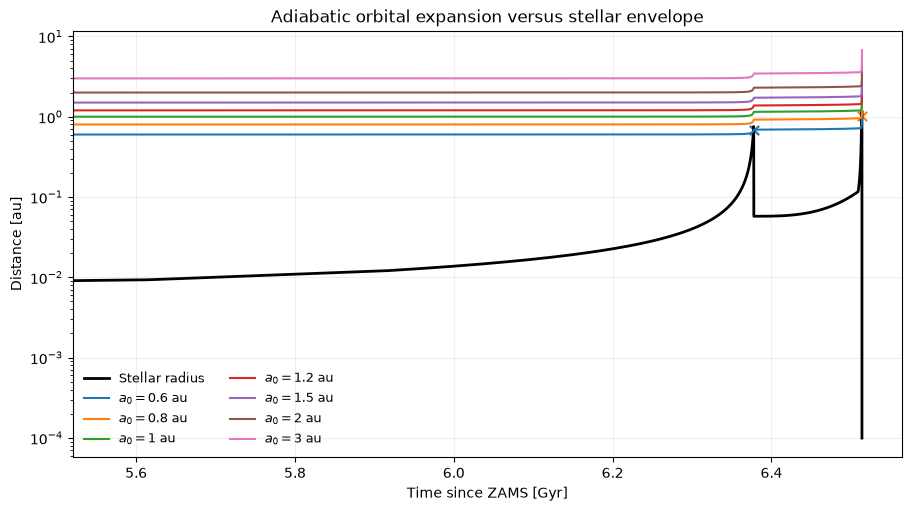

Saved: /home/konaka/Documents/MSc/SMA/AMUSE-Assignements/white_dwarf_project/figures/isolated_planet_pilot.pdf


In [ ]:
planet_mass_MSun = (1.9 | units.MEarth).value_in(units.MSun)
initial_semimajor_axes_AU = np.array([0.6, 0.8, 1.0, 1.2, 1.5, 2.0, 3.0]) # Testing many initial orbits, these can be anything but staying near 1 AU as we saw in the previous notebook its around this distance the star expands to.
initial_eccentricity = 0.0 # An appproximation! We will maybe test with a more realistic eccentricity later.

# Adiabatic response. Eccentricity is constant in this approximation.
expansion_factor = (mass_MSun[0] + planet_mass_MSun) / (mass_MSun + planet_mass_MSun)

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.plot(age_Gyr, radius_AU, color="black", linewidth=2, label="Stellar radius")

for a0 in initial_semimajor_axes_AU:
    a = a0 * expansion_factor
    q = a * (1 - initial_eccentricity)
    indices = np.flatnonzero(q <= radius_AU)
    label = f"$a_0={a0:g}$ au"
    line, = ax.plot(age_Gyr, q, label=label)
    if len(indices):
        i = int(indices[0])
        ax.scatter(age_Gyr[i], q[i], color=line.get_color(), marker="x", s=45)

ax.set_yscale("log")
ax.set_xlabel("Time since ZAMS [Gyr]")
ax.set_ylabel("Distance [au]")
ax.set_title("Adiabatic orbital expansion versus stellar envelope")
ax.legend(ncol=2, frameon=False, fontsize=9)
ax.grid(alpha=0.2)

# Focusing on late stellar evolution while still keeping the main sequence visible.
giant = np.flatnonzero(np.isin(track["stellar_type"], [2, 3, 4, 5, 6]))
if len(giant):
    ax.set_xlim(max(0, age_Gyr[giant[0]] - 0.1), age_Gyr[-1] + 0.05)

figure_path = ROOT / "figures" / "isolated_planet_pilot.pdf"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

## 2. Geometric survival boundary

For an initially fixed eccentricity, the first crossing occurs when

$ a_0(1-e_0)\frac{M_0+m_p}{M(t)+m_p}\le R_\star(t).$

Therefore the minimum initial semimajor axis that avoids radius crossing is estimated by taking the maximum over the saved track.

In [ ]:
a_critical_AU = np.max(
    radius_AU * (mass_MSun + planet_mass_MSun)
    / ((mass_MSun[0] + planet_mass_MSun) * (1 - initial_eccentricity))
)
print(f"Pilot geometric survival boundary: a0 > {a_critical_AU:.3f} au")
print("This excludes tides, brown-dwarf perturbations, and detailed envelope physics.")

print("\nInitial orbit outcomes (sampled stellar track):")
for a0 in initial_semimajor_axes_AU:
    q = a0 * (1 - initial_eccentricity) * expansion_factor
    crossing = np.flatnonzero(q <= radius_AU)
    label = f"crosses envelope at {age_Gyr[crossing[0]]:.3f} Gyr" if len(crossing) else "no sampled envelope crossing"
    print(f"  a0 = {a0:4.1f} au: {label}")

# Calculate the critical initial semimajor axis which is the largest initial semimajor axis that would lead to a crossing of the stellar radius at any point during the stars evoltution.
critical_distance = (
    radius_AU
    * (mass_MSun + planet_mass_MSun)
    / (
        (mass_MSun[0] + planet_mass_MSun)
        * (1 - initial_eccentricity)
    )
)

# Find the most dangerous evolutionary moment, the one with the largest critical initial distance.
i_critical = np.argmax(critical_distance)

print("Most restrictive point in stellar evolution:")
print(f"Time: {age_Gyr[i_critical]:.6f} Gyr")
print(f"Stellar mass: {mass_MSun[i_critical]:.4f} Msun")
print(f"Stellar radius: {radius_AU[i_critical]:.4f} AU")
print(f"Orbital expansion factor: {expansion_factor[i_critical]:.4f}")
print(f"Critical initial distance: {critical_distance[i_critical]:.4f} AU")
print(f"Stellar type: {track['stellar_type'][i_critical]}")

Pilot geometric survival boundary: a0 > 0.818 au
This excludes tides, brown-dwarf perturbations, and detailed envelope physics.

Initial orbit outcomes (sampled stellar track):
  a0 =  0.6 au: crosses envelope at 6.377 Gyr
  a0 =  0.8 au: crosses envelope at 6.513 Gyr
  a0 =  1.0 au: no sampled envelope crossing
  a0 =  1.2 au: no sampled envelope crossing
  a0 =  1.5 au: no sampled envelope crossing
  a0 =  2.0 au: no sampled envelope crossing
  a0 =  3.0 au: no sampled envelope crossing
Most restrictive point in stellar evolution:
Time: 6.513720 Gyr
Stellar mass: 0.8902 Msun
Stellar radius: 1.1029 AU
Orbital expansion factor: 1.3479
Critical initial distance: 0.8182 AU
Stellar type: 5


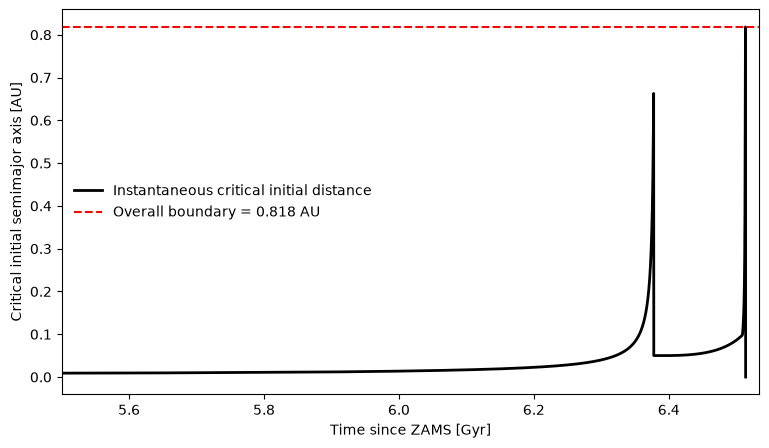

In [ ]:
# This plot shows the critical initial semimajor axis as a function of time, and the overall critical initial semimajor axis as a horizontal line
# which means that any initial semimajor axis below this line will lead to a crossing of the stellar radius at some point during the stars evolution.
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    age_Gyr,
    critical_distance,
    color="black",
    linewidth=2,
    label="Instantaneous critical initial distance"
)

ax.axhline(
    a_critical_AU,
    color="red",
    linestyle="--",
    label=f"Overall boundary = {a_critical_AU:.3f} AU"
)

ax.set_xlabel("Time since ZAMS [Gyr]")
ax.set_ylabel("Critical initial semimajor axis [AU]")

ax.set_xlim(5.5, age_Gyr[-1] + 0.02)

ax.legend(frameon=False)

plt.show()